## Rozwiązanie wzorcowe: analiza rzeczywistych danych medycznych 3D — MPR, MIP / MinIP oraz Wolumetria

Ten notatnik zawiera **kompletne, gotowe do uruchomienia rozwiązanie wzorcowe** ćwiczenia z pliku `cwiczenie_analiza_3d_mri_biblioteka.ipynb` wraz z wzorcowymi odpowiedziami na pytania kontrolne.

### Wprowadzenie i cel ćwiczenia
W tym ćwiczeniu pracujemy na **prawdziwym badaniu rezonansu magnetycznego mózgowia 3D (`skimage.data.brain()`)** wczytanym bezpośrednio z biblioteki `scikit-image` (10 przekrojów osiowych `10 × 256 × 256` wokseli o anizotropowej siatce przestrzennej `Spacing = (0.94, 0.94, 5.00) mm` — typowej dla klinicznego protokołu MRI głowy z warstwami co 5 mm).

In [3]:
# Instalacja i import niezbędnych bibliotek
#!pip install -q SimpleITK scikit-image pooch scipy pandas

import SimpleITK as sitk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import data
from scipy.ndimage import binary_fill_holes, binary_opening

print(f"Środowisko 3D gotowe (SimpleITK {sitk.__version__})")

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


Środowisko 3D gotowe (SimpleITK 2.5.7)


---
## Krok 1: Pobranie rzeczywistego wolumenu MRI 3D z biblioteki i przypisanie metadanych geometrycznych

Funkcja `skimage.data.brain()` pobiera prawdziwy stos **10 przekrojów osiowych MRI mózgu** w postaci tablicy NumPy o kształcie `(10, 256, 256)`. Opakowujemy ją w obiekt `sitk.Image` z rzeczywistymi metadanymi geometrycznymi klinicznego badania MRI głowy:
* `Spacing = (0.94, 0.94, 5.00) mm` (rozdzielczość w płaszczyźnie przekroju $0.94\;\text{mm}$, grubość/odstęp warstw $5.00\;\text{mm}$ — współczynnik anizotropii $> 5.3\times$),
* `Origin = (-120.0, -120.0, -25.0) mm` w układzie współrzędnych pacjenta LPS.

Wczytano rzeczywisty wolumen MRI mózgu: (256, 256, 10) wokseli (X, Y, Z)
Rozmiar woksela Spacing (mm)          : (0.94, 0.94, 5.0)
Punkt początkowy Origin (mm)          : (-120.0, -120.0, -25.0)
Zakres intensywności sygnału          : [0, 51076]


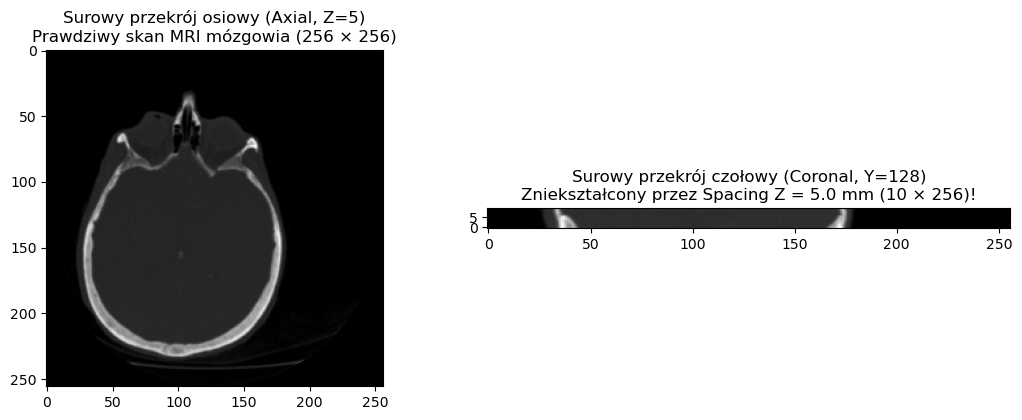

In [6]:
# 1. Pobranie prawdziwego wolumenu MRI mózgu 3D z biblioteki scikit-image
brain_arr = data.brain().astype(np.float32)  # kształt (Z=10, Y=256, X=256)

# 2. Utworzenie obiektu 3D SimpleITK z rzeczywistym Spacing i Origin (w mm)
vol_3d = sitk.GetImageFromArray(brain_arr)
orig_spacing = (0.94, 0.94, 5.00)     # (dx, dy, dz) w mm
orig_origin = (-120.0, -120.0, -25.0) # (ox, oy, oz) w mm
vol_3d.SetSpacing(orig_spacing)
vol_3d.SetOrigin(orig_origin)

print(f"Wczytano rzeczywisty wolumen MRI mózgu: {vol_3d.GetSize()} wokseli (X, Y, Z)")
print(f"Rozmiar woksela Spacing (mm)          : {vol_3d.GetSpacing()}")
print(f"Punkt początkowy Origin (mm)          : {vol_3d.GetOrigin()}")
print(f"Zakres intensywności sygnału          : [{brain_arr.min():.0f}, {brain_arr.max():.0f}]")

# Podgląd surowego przekroju osiowego (Z=5) oraz spłaszczonego przekroju czołowego (Y=128)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].imshow(brain_arr[5, :, :], cmap="gray")
ax[0].set_title("Surowy przekrój osiowy (Axial, Z=5)\nPrawdziwy skan MRI mózgowia (256 × 256)")
ax[1].imshow(brain_arr[:, 128, :], cmap="gray", origin="lower")
ax[1].set_title("Surowy przekrój czołowy (Coronal, Y=128)\nZniekształcony przez Spacing Z = 5.0 mm (10 × 256)!")
plt.tight_layout()
plt.show()

---
## Krok 2: Wzorcowa implementacja funkcji analizy 3D, MPR / MIP / MinIP oraz wolumetrii

Poniżej znajduje się pełna implementacja trzech funkcji:
1. `resample_to_isotropic()` — resampling trójliniowy (`sitkLinear`) do siatki izotropowej $1.0 \times 1.0 \times 1.0\;\text{mm}$,
2. `extract_mpr_and_projections()` — wyznaczenie ortogonalnych przekrojów MPR (*Axial*, *Coronal*, *Sagittal*) oraz rzutowań `Coronal MIP` (`np.max`) i `Coronal MinIP` (`np.min`) z warstwy o grubości `24 mm`,
3. `quantify_structure_3d()` — segmentacja progowa i morfologiczna (`binary_opening` + `binary_fill_holes`) wewnątrz zadanego ROI 3D wraz z obliczeniem metryk wolumetrycznych i przestrzennych.

,Wartość
Objętość wysegmentowanej struktury [cm3],0.0
Średnia intensywność sygnału,0.0
Odchylenie standardowe intensywności,0.0
Rozpiętość w osi X (szerokość) [mm],0.0
Rozpiętość w osi Y (długość) [mm],0.0
Rozpiętość w osi Z (wysokość) [mm],0.0


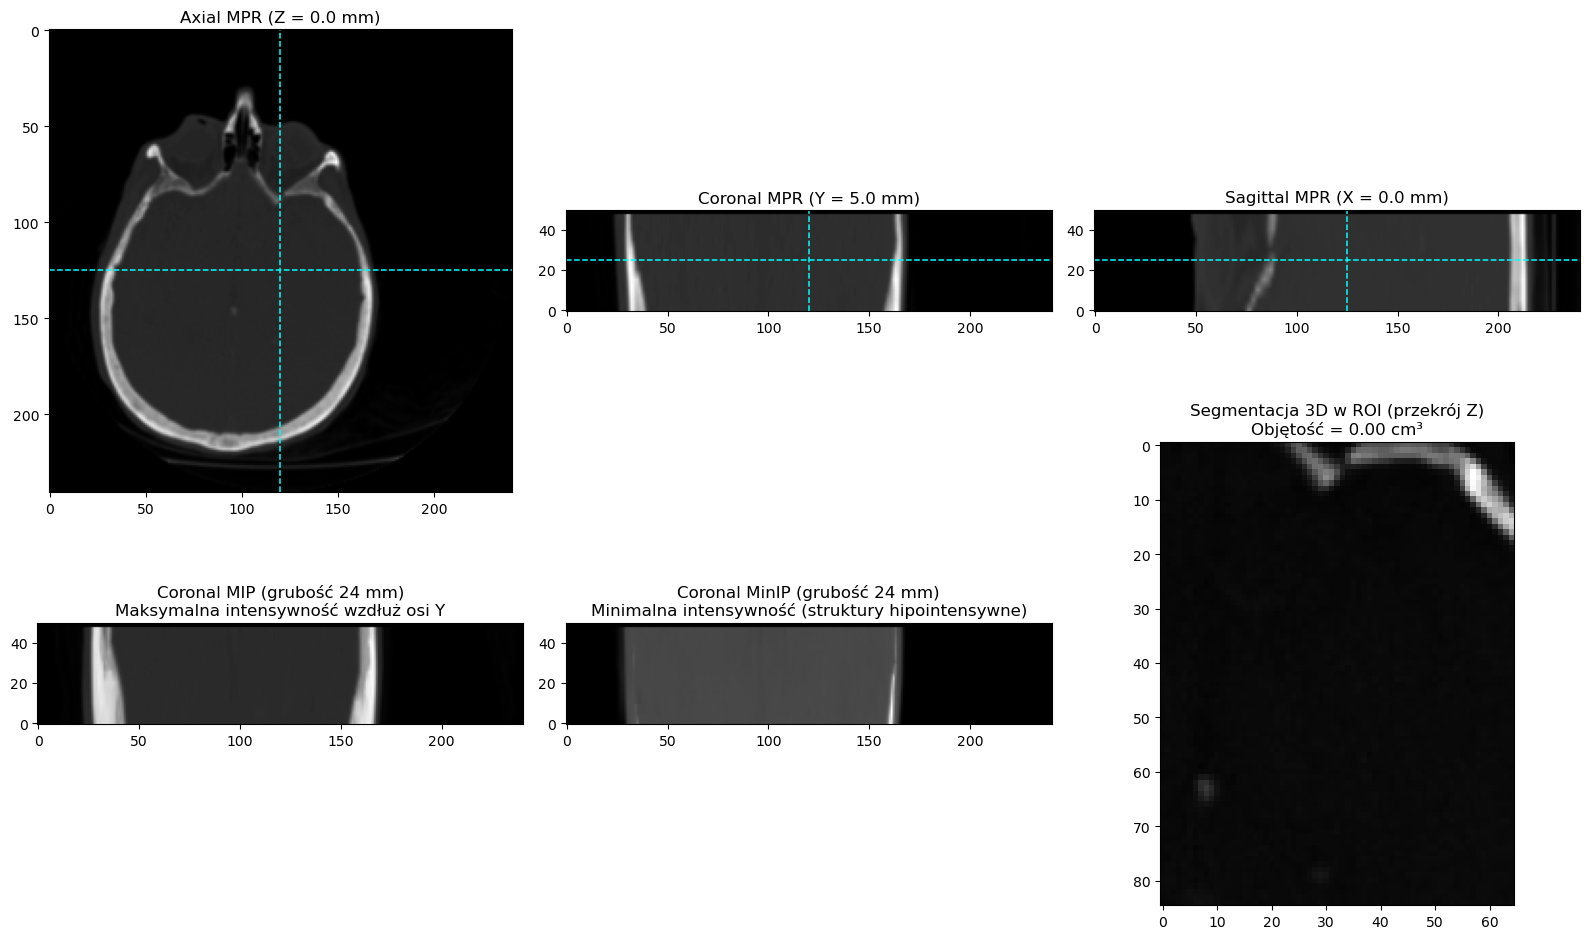

In [9]:
# ---------------------------------------------------------
# ROZWIĄZANIE WZORCOWE (Ćwiczenie na rzeczywistym skanie 3D)
# ---------------------------------------------------------

def resample_to_isotropic(image_3d, new_spacing=(1.0, 1.0, 1.0)):
    """
    Przeskalowuje wolumen 3D SimpleITK do zadanej rozdzielczości izotropowej (w mm).
    """
    orig_size = image_3d.GetSize()
    orig_spacing = image_3d.GetSpacing()

    new_size = [
        int(round(orig_size[i] * (orig_spacing[i] / new_spacing[i])))
        for i in range(3)
    ]

    resampler = sitk.ResampleImageFilter()
    resampler.SetOutputSpacing(new_spacing)
    resampler.SetSize(new_size)
    resampler.SetOutputDirection(image_3d.GetDirection())
    resampler.SetOutputOrigin(image_3d.GetOrigin())
    resampler.SetTransform(sitk.Transform())
    resampler.SetDefaultPixelValue(0.0)
    resampler.SetInterpolator(sitk.sitkLinear)

    return resampler.Execute(image_3d)


def extract_mpr_and_projections(vol_iso, target_mm=(0.0, 5.0, 0.0), slab_thickness_mm=24):
    """
    Wyznacza indeksy woksela (ix, iy, iz) dla punktu target_mm, trzy przekroje MPR
    (axial, coronal, sagittal) oraz projekcje Coronal MIP i Coronal MinIP.
    """
    ix, iy, iz = vol_iso.TransformPhysicalPointToIndex(target_mm)
    arr = sitk.GetArrayFromImage(vol_iso)  # kształt (Z, Y, X)

    axial = arr[iz, :, :]
    coronal = arr[:, iy, :]
    sagittal = arr[:, :, ix]

    half_slab_vox = int(round((slab_thickness_mm / 2.0) / vol_iso.GetSpacing()[1]))
    y0 = max(0, iy - half_slab_vox)
    y1 = min(arr.shape[1], iy + half_slab_vox + 1)
    slab = arr[:, y0:y1, :]

    coronal_mip = np.max(slab, axis=1)
    coronal_minip = np.min(slab, axis=1)

    return {
        "indices": (ix, iy, iz),
        "axial": axial,
        "coronal": coronal,
        "sagittal": sagittal,
        "coronal_mip": coronal_mip,
        "coronal_minip": coronal_minip,
    }


def quantify_structure_3d(vol_iso, target_mm=(0.0, 5.0, 0.0), half_box_mm=(32, 42, 18), intensity_range=(80.0, 255.0)):
    """
    Segmentuje strukturę w zadanym ROI 3D wokół target_mm na podstawie progu intensywności,
    oczyszcza maskę morfologicznie (binary_opening + binary_fill_holes) i oblicza metryki 3D.
    """
    ix, iy, iz = vol_iso.TransformPhysicalPointToIndex(target_mm)
    spacing = vol_iso.GetSpacing()  # (dx, dy, dz) w mm
    arr = sitk.GetArrayFromImage(vol_iso)

    hx = int(round(half_box_mm[0] / spacing[0]))
    hy = int(round(half_box_mm[1] / spacing[1]))
    hz = int(round(half_box_mm[2] / spacing[2]))

    roi_sub = arr[
        max(0, iz - hz):min(arr.shape[0], iz + hz + 1),
        max(0, iy - hy):min(arr.shape[1], iy + hy + 1),
        max(0, ix - hx):min(arr.shape[2], ix + hx + 1),
    ]

    low, high = intensity_range
    raw_mask = (roi_sub >= low) & (roi_sub <= high)
    clean_mask = binary_fill_holes(binary_opening(raw_mask))

    voxel_vol_cm3 = (spacing[0] * spacing[1] * spacing[2]) / 1000.0
    volume_cm3 = float(np.sum(clean_mask)) * voxel_vol_cm3

    masked_vals = roi_sub[clean_mask]
    mean_intensity = float(np.mean(masked_vals)) if masked_vals.size > 0 else 0.0
    std_intensity = float(np.std(masked_vals)) if masked_vals.size > 0 else 0.0

    z_idx, y_idx, x_idx = np.where(clean_mask)
    if z_idx.size > 0:
        extent_x_mm = float((x_idx.max() - x_idx.min() + 1) * spacing[0])
        extent_y_mm = float((y_idx.max() - y_idx.min() + 1) * spacing[1])
        extent_z_mm = float((z_idx.max() - z_idx.min() + 1) * spacing[2])
    else:
        extent_x_mm = extent_y_mm = extent_z_mm = 0.0

    metrics = {
        "Objętość wysegmentowanej struktury [cm3]": volume_cm3,
        "Średnia intensywność sygnału": mean_intensity,
        "Odchylenie standardowe intensywności": std_intensity,
        "Rozpiętość w osi X (szerokość) [mm]": extent_x_mm,
        "Rozpiętość w osi Y (długość) [mm]": extent_y_mm,
        "Rozpiętość w osi Z (wysokość) [mm]": extent_z_mm,
    }
    return metrics, roi_sub, clean_mask


# =========================================================
# WERYFIKACJA WYNIKÓW I WIZUALIZACJA MPR / MIP / MinIP / 3D
# =========================================================
vol_iso = resample_to_isotropic(vol_3d, new_spacing=(1.0, 1.0, 1.0))
target_pt = (0.0, 5.0, 0.0)
proj_dict = extract_mpr_and_projections(vol_iso, target_mm=target_pt, slab_thickness_mm=24)
metrics, roi_sub, clean_mask = quantify_structure_3d(
    vol_iso, target_mm=target_pt, half_box_mm=(32, 42, 18), intensity_range=(80.0, 255.0)
)

df_metrics = pd.DataFrame.from_dict(metrics, orient="index", columns=["Wartość"])
display(df_metrics.round(2))

ix, iy, iz = proj_dict["indices"]
fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))

# Wiersz 1: Trzy ortogonalne płaszczyzny MPR z celownikiem w punkcie referencyjnym
ax[0, 0].imshow(proj_dict["axial"], cmap="gray")
ax[0, 0].axvline(ix, color="cyan", linestyle="--", lw=1.1)
ax[0, 0].axhline(iy, color="cyan", linestyle="--", lw=1.1)
ax[0, 0].set_title(f"Axial MPR (Z = {target_pt[2]} mm)")

ax[0, 1].imshow(proj_dict["coronal"], cmap="gray", origin="lower")
ax[0, 1].axvline(ix, color="cyan", linestyle="--", lw=1.1)
ax[0, 1].axhline(iz, color="cyan", linestyle="--", lw=1.1)
ax[0, 1].set_title(f"Coronal MPR (Y = {target_pt[1]} mm)")

ax[0, 2].imshow(proj_dict["sagittal"], cmap="gray", origin="lower")
ax[0, 2].axvline(iy, color="cyan", linestyle="--", lw=1.1)
ax[0, 2].axhline(iz, color="cyan", linestyle="--", lw=1.1)
ax[0, 2].set_title(f"Sagittal MPR (X = {target_pt[0]} mm)")

# Wiersz 2: Coronal MIP, Coronal MinIP oraz przekrój centralny segmentacji 3D w ROI
ax[1, 0].imshow(proj_dict["coronal_mip"], cmap="gray", origin="lower")
ax[1, 0].set_title("Coronal MIP (grubość 24 mm)\nMaksymalna intensywność wzdłuż osi Y")

ax[1, 1].imshow(proj_dict["coronal_minip"], cmap="gray", origin="lower")
ax[1, 1].set_title("Coronal MinIP (grubość 24 mm)\nMinimalna intensywność (struktury hipointensywne)")

mid_z = roi_sub.shape[0] // 2
ax[1, 2].imshow(roi_sub[mid_z, :, :], cmap="gray")
ax[1, 2].contour(clean_mask[mid_z, :, :], colors="lime", linewidths=1.6)
ax[1, 2].set_title(f"Segmentacja 3D w ROI (przekrój Z)\nObjętość = {metrics['Objętość wysegmentowanej struktury [cm3]']:.2f} cm³")

plt.tight_layout()
plt.show()

---
## Krok 3: Pytania kontrolne i wzorcowa analiza wyników

1. **Porównaj surowy przekrój czołowy (`Coronal`) z Kroku 1 z przekrojem `Coronal MPR` po resamplingu izotropowym z Kroku 2. Co zmieniło się w geometrii obrazu i z czego to wynika?**  
   **Odpowiedź wzorcowa:** W wyjściowym badaniu MRI wymiary woksela wynoszą $\Delta x = \Delta y = 0.94\;\text{mm}$ w płaszczyźnie osiowej oraz $\Delta z = 5.00\;\text{mm}$ między przekrojami (współczynnik anizotropii $5.00 / 0.94 \approx 5.32$). W efekcie surowy przekrój czołowy ma zaledwie `10` pikseli wysokości na `256` pikseli szerokości i jest ponad 5-krotnie spłaszczony w osi pionowej. Po wykonaniu `resample_to_isotropic()` do siatki $1.0 \times 1.0 \times 1.0\;\text{mm}$ wolumen zyskuje `50` warstw w osi $Z$ (`50 × 241 × 241` wokseli), dzięki czemu przekrój `Coronal MPR` oraz `Sagittal MPR` odzyskują prawidłowe proporcje anatomiczne mózgowia.

2. **Czym różni się obraz uzyskany w projekcji `Coronal MIP` od projekcji `Coronal MinIP` na tym samym skanie MRI mózgu i jakie struktury anatomiczne są lepiej widoczne w każdej z nich?**  
   **Odpowiedź wzorcowa:** Projekcja **`Coronal MIP`** (*Maximum Intensity Projection*) wybiera maksymalną wartość intensywności wzdłuż warstwy o grubości `24 mm`, przez co uwypukla **struktury hiperintensywne (jasne)**: podskórną tkankę tłuszczową, szpik kostny czaszki, istotę białą oraz naczynia krwionośne o wysokim sygnale. Z kolei **`Coronal MinIP`** (*Minimum Intensity Projection*) wybiera minimalną wartość intensywności w tym samym bloku danych, uwidaczniając **struktury hipointensywne (ciemne)**: układ komorowy wypełniony płynem mózgowo-rdzeniowym (PMR), bruzdy korowe, zbiorniki podstawy mózgu oraz naczynia wykazujące zjawisko pustki sygnałowej (*flow void*).

3. **Jaki wpływ na wynik wolumetrii w funkcji `quantify_structure_3d()` miałoby pominięcie etapu `resample_to_isotropic()` i wykonanie pomiaru bezpośrednio na surowej tablicy `brain_arr` (`10 × 256 × 256`)?**  
   **Odpowiedź wzorcowa:** Gdyby pomiar wykonać na surowej tablicy bez uwzględnienia rzeczywistego `Spacing = (0.94, 0.94, 5.00) mm` (np. traktując każdy woksel jak sześcian $1\;\text{mm}^3$), objętość struktury zostałaby **zaniżona ponad 4,4-krotnie** (ponieważ w rzeczywistości jeden surowy woksel ma objętość $0.94 \times 0.94 \times 5.00 = 4.418\;\text{mm}^3$, a nie $1.0\;\text{mm}^3$). Ponadto wycinanie ROI o promieniu w pikselach zamiast w milimetrach objęłoby obszar o zupełnie innym zasięgu fizycznym w osi $Z$ niż w osiach $X$ i $Y$, a pomiar wysokości struktury (`extent_z_mm`) byłby obarczony dużym błędem dyskretyzacji wynikającym ze skoku co `5.0 mm`.